Shock Obervations: 193
Ticker           XLI       TLT      NVDA
Date                                    
2019-01-03 -0.030902  0.011315 -0.062319
2019-01-04  0.037215 -0.011642  0.062098
2019-05-23 -0.015339  0.011185 -0.032588
2019-07-05 -0.003991 -0.013352 -0.015605
2019-08-01 -0.019594  0.019666 -0.022780
...              ...       ...       ...
2025-10-10 -0.022363  0.016018 -0.050100
2026-03-20 -0.014675 -0.019156 -0.033369
2026-03-30 -0.016403  0.013224 -0.014127
2026-05-15 -0.017982 -0.014949 -0.045208
2026-05-20  0.011724  0.010663  0.012881

[193 rows x 3 columns]
Shock observations: 193
Normal observations: 1713
Comparison of Normal and Shock Log-Returns


,Shock,Normal
Ticker,,
XLI,-0.003162,0.001045
TLT,-0.001497,0.000070
NVDA,-0.000737,0.002500


Average Relative Performance Comparison


,Market Condition,Average Relative Performance
0,Shock Days,0.002425
1,Normal Days,0.001455
2,Difference on Shock,0.000969


Outperformance Comparison


,Market Condition,NVDA outperfomed XLI,XLI outperformed NVDA
0,Shock Days,110,83
1,Normal Days,895,818


... (8 outputs left out)

Daily Volatility Comparison


,Shock Daily Volatility,Normal Daily Volatility,Shock Annual Volatility,Normal Annual Volatility
XLI,0.022569,0.012108,0.358275,0.192208
TLT,0.021732,0.007768,0.344991,0.123310
NVDA,0.047448,0.029509,0.753222,0.468440


Distribution Comparison


,Shock Skewness,Normal Skewness,Shock Kurtosis,Normal Kurtosis
Ticker,,,,
XLI,-0.690223,-0.029685,7.083994,11.429469
TLT,0.249563,-0.034256,0.118082,0.341937
NVDA,0.136122,-0.009064,4.813733,2.161564


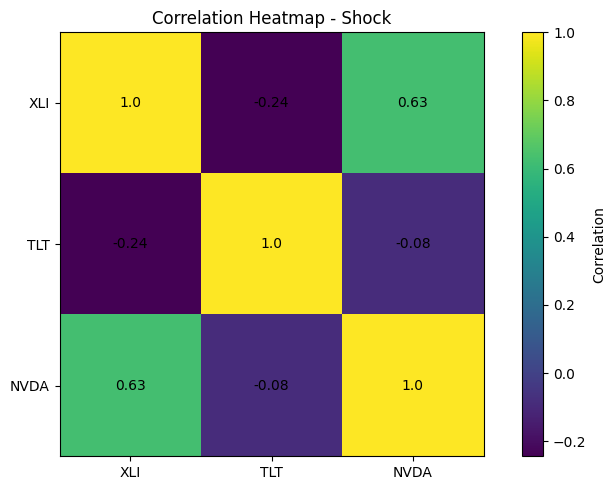

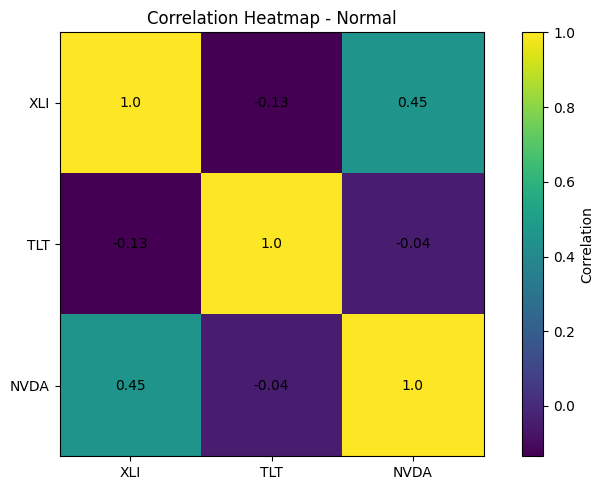

In [4]:
#--------------------------
# Empirical Analysis
#--------------------------

# 1. Imports
# 2. Load data
# 3. Calculate log returns
# 4. Create interest rate shock mask (including lags)
# 5. Split data into
#    - normal periods
#    - shock periods
# 6. Compare returns in different approchaes
# 7. Dependence structure (Coor-Heatmap, Covar-Matrices)
# 8. Risk characteristics
# 9. Portfolio optimaziation (Weights for every lag)
# 10. Portfolio performance matrices for 9.


#1. Imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))
OUTPUT_DIR = Path.home() / "Desktop" / "Projekte" / "Quant1_NB_02_Output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import dataloader
import mathematical_framework
import plotting

import importlib
importlib.reload(mathematical_framework)

#2. Load data
data = dataloader.load_all_project_data()
portfolio_assets, yield_10y = dataloader.split_project_data(data)

#3. Calculate log-returns
returns = mathematical_framework.calculate_log_returns(portfolio_assets)

#4. Everything with shocks
yield_change_bps = yield_10y.squeeze().diff() * 100
shock_mask = mathematical_framework.detect_rate_shock_mask(yield_change_bps)

returns, shock_mask = returns.align(shock_mask, join="inner", axis=0)
shock_returns = returns[shock_mask]

print(f"Shock Obervations: {len(shock_returns)}")
print(shock_returns)

#5. Splitting return data
shock_returns = returns[shock_mask]
normal_returns = returns[~shock_mask]

#Test:
print(f"Shock observations: {len(shock_returns)}")
print(f"Normal observations: {len(normal_returns)}")

#6. Comparing returns
comparison = pd.DataFrame({"Shock": shock_returns.mean(), "Normal": normal_returns.mean()})
comparison.to_latex(OUTPUT_DIR / "Comparison_of_Normal_and_Shock_Log-Returns.tex",float_format="%.4f")
print("Comparison of Normal and Shock Log-Returns")
display(comparison)

normal_relative = mathematical_framework.relative_interest_rate_sensitivity(normal_returns)
shock_relative = mathematical_framework.relative_interest_rate_sensitivity(shock_returns)

# Asset 1 is NVDA, so neg is that XLI is better and vice versa
performance_comparison = pd.DataFrame({"Market Condition": ["Shock Days", "Normal Days", "Difference on Shock"], "Average Relative Performance": 
    [shock_relative.mean(), normal_relative.mean(), shock_relative.mean() - normal_relative.mean()]})
performance_comparison.to_latex(OUTPUT_DIR / "Average_Relative_Performance_Comparison.tex", float_format="%.4f")
print("Average Relative Performance Comparison")
display(performance_comparison)

outperformance_comparison = pd.DataFrame({"Market Condition": ["Shock Days", "Normal Days"], "NVDA outperfomed XLI": [(shock_relative > 0).sum(),
    (normal_relative > 0).sum()], "XLI outperformed NVDA": [(shock_relative < 0).sum(), (normal_relative < 0).sum()]})
outperformance_comparison.to_latex(OUTPUT_DIR / "Ouperformance_Comparison.tex", float_format="%.4f")
print("Outperformance Comparison")
display(outperformance_comparison)

median_comparison = pd.DataFrame({"Shock Median": shock_returns.median(), "Normal Median": normal_returns.median()})
median_comparison.to_latex(OUTPUT_DIR / "Median-Return_Comparison.tex", float_format="%.4f")
print("Median-Return Comparison")
display(median_comparison)

#---------------------------
# More quantitative analysis
#---------------------------

#7. Dependence structure
importlib.reload(plotting)

plotting.plot_correlation_heatmap(shock_returns,title="Correlation Heatmap - Shock")
plt.savefig(OUTPUT_DIR / "Correlation_Heatmap_Shock.pdf", bbox_inches="tight")

plotting.plot_correlation_heatmap(normal_returns, title="Correlation Heatmap - Normal")
plt.savefig(OUTPUT_DIR / "Correlation_Heatmap_Normal.pdf", bbox_inches="tight")

shock_cov = shock_returns.cov()
shock_cov = shock_cov.rename_axis(index=None, columns=None)
shock_cov.to_latex(OUTPUT_DIR / "Covariance_Matrix-Shock.tex", float_format="%.6f")
print("Covariance Matrix - Shock")
display(shock_cov)

normal_cov = normal_returns.cov()
normal_cov = normal_cov.rename_axis(index=None, columns=None)
normal_cov.to_latex(OUTPUT_DIR / "Covariance_Matrix-Normal.tex", float_format="%.6f")
print("Covariance Matrix - Normal")
display(normal_cov)

yield_change_bps = yield_change_bps.loc[returns.index]

shock_yield_corr = mathematical_framework.correlation_with_yield_changes(shock_returns, yield_change_bps)

normal_yield_corr = mathematical_framework.correlation_with_yield_changes(normal_returns, yield_change_bps)

shock_yield_comparison = pd.DataFrame({"Shock-Yield-Corr": shock_yield_corr, "Normal-Yield-Corr": normal_yield_corr})
shock_yield_comparison.to_latex(OUTPUT_DIR / "Normal_Shock_Correlation_with_Yield.tex", float_format="%.4f")
print("Normal/ Shock Correlation with Yield")
display(shock_yield_comparison)

#8. Risk characteristics
shock_vol = shock_returns.std()
normal_vol = normal_returns.std()

shock_vol_annual = shock_returns.std() * np.sqrt(252)
normal_vol_annual = normal_returns.std() * np.sqrt(252)

vol_comparison = pd.DataFrame({"Shock Daily Volatility": shock_vol, "Normal Daily Volatility": normal_vol,"Shock Annual Volatility": shock_vol_annual,
    "Normal Annual Volatility": normal_vol_annual})
vol_comparison.to_latex(OUTPUT_DIR / "Daily_Volatility_Comparison.tex", float_format="%.4f")
print("Daily Volatility Comparison")
display(vol_comparison.rename_axis(index=None, columns=None))

shock_skew = shock_returns.skew()
shock_kurt = shock_returns.kurt()

normal_skew = normal_returns.skew()
normal_kurt = normal_returns.kurt()

distrib_comparison = pd.DataFrame({"Shock Skewness": shock_skew, "Normal Skewness": normal_skew, "Shock Kurtosis": shock_kurt,
    "Normal Kurtosis": normal_kurt})
distrib_comparison.to_latex(OUTPUT_DIR / "Distribution_Comparison.tex", float_format="%.3f")
print("Distribution Comparison")
display(distrib_comparison)